# 06 — Physics baselines: ETAS, rate-and-state, and the hybrid

**Question (Part 2, `docs/plan_v2.md`):** Part 1 found that GPS uplift adds no measurable weekly forecasting skill beyond past seismicity, but it only compared the ML models with simple benchmarks. Two physics models are much stronger benchmarks:

- **ETAS** (Epidemic-Type Aftershock Sequence): every earthquake raises the chance of further earthquakes for a while (Omori's law), more so for larger ones. It uses past earthquakes only.
- **The hybrid of Hainzl, Dahm & Tramelli (2026)**: ETAS whose background rate comes from a **rate-and-state (RS)** model driven by the uplift since 1905.

This notebook:

1. implements the three models and checks them against the authors' published results (milestone 3);
2. *(milestone 4)* turns them into weekly forecasts and compares them with the Part 1 models on the same test weeks and scores.

## 1. The models, implemented and checked

The rate of earthquakes with M ≥ 0.45 (Md ≥ 0.5 at 0.1 resolution) at time t, in events per day:

$$\lambda(t) = \mu(t) + \sum_{t - 100\,\text{d} \le t_i < t} K\, 10^{\alpha (m_i - 0.45)}\, (c + t - t_i)^{-p}$$

- **ETAS:** μ is a constant. K (productivity), α (how much more productive larger events are), c and p (Omori's law) describe triggering. As in Hainzl et al., an event only triggers for 100 days.
- **RS:** no triggering. The rate responds to the stress S(t), here the uplift in metres plus a slow background loading Aσ′/t_a per day:
  $$\mu(t) = \frac{r\, e^{S(t)/A\sigma'}}{1 + \frac{1}{t_a}\int_{1905}^{t} e^{S/A\sigma'}\,dt'}$$
  The numerator makes the rate rise steeply when the uplift reaches new heights. The denominator remembers how much of the fault population earlier uplift has already used up: this is why the whole history since 1905 matters, including the 1950s, 1970s and 1980s episodes.
- **RS + ETAS (the hybrid):** ETAS with the RS rate as its background μ(t).

**Fitting** is by maximum likelihood: log L = Σ log λ(tᵢ) − ∫ λ dt over the window (high rates where earthquakes happened, few expected overall). As in the paper, the window runs from 2005.0 to the end of their uplift file (5 Feb 2025), and events before 2005 still count as triggers. (Their code converts 2005.0 to days with a straight-line fit of decimal year against date, which lands half a day early, on 31 Dec 2004; we keep it to fit exactly the same data.) Time is in days.

**Code:** `src/physics.py`, adapted from the authors' Python code (Hainzl 2026, Zenodo, doi:10.5281/zenodo.18413119, CC BY 4.0). The likelihood is theirs; the RS rate is computed in log space (no overflow), the triggering sums are vectorised, and fits use bounds and several starting points.

**Data:** their files in `data/raw/hainzl/` (fetched by `scripts/download_data.py`): the uplift since 1905 (`gps.dat`: levelling, then GPS station RITE) and their catalogue (`campi-flegrei.kat`, from GOSSIP).

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.completeness import b_value_mle
from src.gps import MJD_EPOCH
from src.physics import (FIT_START_YEAR, MCUT, MODELS, branching_ratio, expected_counts, fit, intensities,
                         load_catalogue, load_uplift, negative_log_likelihood, prepare, simulate_etas, year_to_mjd)

HAINZL = Path("../data/raw/hainzl")
DAYS_PER_YEAR = 365.25
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def to_time(mjd):
    return MJD_EPOCH + pd.to_timedelta(np.asarray(mjd), unit="D")


uplift, events = load_uplift(HAINZL), load_catalogue(HAINZL)
t1, t2 = year_to_mjd(FIT_START_YEAR, uplift), uplift["mjd"].iloc[-1]
data = prepare(events, uplift, t1, t2)
print(f"Uplift: {len(uplift)} weeks, {uplift['year'].iloc[0]:.1f} to {uplift['year'].iloc[-1]:.2f}")
print(f"Fit window: {to_time(t1):%Y-%m-%d} to {to_time(t2):%Y-%m-%d}")
print(f"Events with M ≥ {MCUT}: {len(data['t'])} up to the window's end, {len(data['target'])} in the window")

Uplift: 6258 weeks, 1905.2 to 2025.10
Fit window: 2004-12-31 to 2025-02-05
Events with M ≥ 0.45: 4305 up to the window's end, 4250 in the window


### 1.1 Their catalogue against ours

Their catalogue should be the GOSSIP catalogue we cleaned in phase 3. Events with M ≥ 0.45 since 2005, by year, up to the end of their file (25 Feb 2025):

In [2]:
ours = pd.read_parquet("../data/processed/catalogue.parquet")
start, end = pd.Timestamp("2005-01-01", tz="UTC"), to_time(events["mjd"].max())
ours = ours[(ours["time"] >= start) & (ours["time"] <= end) & (ours["md"] >= MCUT)]
theirs = pd.Series(to_time(events["mjd"]))
theirs = theirs[theirs >= start]
pd.DataFrame({"theirs": theirs.dt.year.value_counts(), "ours": ours["time"].dt.year.value_counts()}).sort_index().T

,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
theirs,17,16,1,4,2,14,8,26,1,19,28,38,33,95,118,177,222,379,1177,1774,735
ours,17,16,1,4,2,14,8,26,1,19,28,38,33,95,118,177,222,379,1177,1775,808


### 1.2 Same likelihood as the authors' code?

The authors' files give their fitted parameters and the resulting −log L. If our code computes the same −log L at their parameters, the two implementations agree. (During development, our RS rate also matched their function to 1e-13 at several parameter sets.)

In [3]:
def read_published(name, keys):
    """One row of fitted parameters from the authors' parameter-*.dat files (time in days)."""
    return dict(zip(keys, np.loadtxt(HAINZL / name)))


published = {
    "rs": read_published("parameter-RS.dat", ["r", "asig", "ta", "nll", "aic"]),
    "rs_etas": read_published("parameter-RSETAS.dat", ["r", "asig", "ta", "K", "alpha", "c", "p", "nll", "aic"]),
}
for model, values in published.items():
    params = {k: values[k] for k in MODELS[model]}
    print(f"{model:8s} -log L at their parameters: ours {negative_log_likelihood(params, data, model):10.3f}, "
          f"their file {values['nll']:10.3f}")

rs       -log L at their parameters: ours   1229.636, their file   1229.636
rs_etas  -log L at their parameters: ours  -4125.891, their file  -4125.892


### 1.3 Fitting the three models

Each model is fitted from the authors' starting point plus 4 random ones (seeded). α, c and p trade off against each other, so the likelihood has long, flat valleys, and one start can get stuck. A constant-rate Poisson model is added for reference. AIC = 2·(−log L) + 2·(number of parameters): lower is better, and a difference of more than about 10 is decisive.

In [4]:
fits = {}
for model in MODELS:
    start = time.perf_counter()
    fits[model] = fit(data, model)
    print(f"{model}: fitted in {time.perf_counter() - start:.0f} s")

n = len(data["target"])
poisson_nll = n - n * np.log(n / (t2 - t1))
comparison = pd.DataFrame({m: {"parameters": len(MODELS[m]), "-log L": f["nll"], "AIC": f["aic"]}
                           for m, f in fits.items()}).T
comparison.loc["poisson"] = [1, poisson_nll, 2 * poisson_nll + 2]
comparison["AIC - hybrid's"] = comparison["AIC"] - comparison.loc["rs_etas", "AIC"]
comparison.round(1)

etas: fitted in 15 s


rs: fitted in 0 s


rs_etas: fitted in 60 s


,parameters,-log L,AIC,AIC - hybrid's
etas,5.0,-4046.3,-8082.5,155.3
rs,3.0,1229.6,2465.3,10703.1
rs_etas,7.0,-4125.9,-8237.8,0.0
poisson,1.0,6572.5,13147.1,21384.9


Our hybrid fit against Table 1 of Hainzl et al. (2026) and their parameter file, in the paper's units (rates per year, t_a in years):

In [5]:
def in_paper_units(p):
    return {"r (events/yr)": p["r"] * DAYS_PER_YEAR, "Aσ′ (m)": p["asig"], "t_a (yr)": p["ta"] / DAYS_PER_YEAR,
            "K": p["K"], "α": p["alpha"], "c (days)": p["c"], "p": p["p"]}


pd.DataFrame({
    "Table 1": {"r (events/yr)": 7.5, "Aσ′ (m)": 0.20, "t_a (yr)": 34.2, "K": 0.04, "α": 0.24, "p": 1.08},
    "their file": in_paper_units(published["rs_etas"]),
    "our fit": in_paper_units(fits["rs_etas"]["params"]),
}).round(4)

,Table 1,their file,our fit
r (events/yr),7.50,7.4679,7.4790
Aσ′ (m),0.20,0.1973,0.1971
t_a (yr),34.20,34.2074,34.3790
K,0.04,0.0428,0.0427
α,0.24,0.2416,0.2418
p,1.08,1.0811,1.0827
c (days),NaN,0.0006,0.0006


Did the starts agree? Each row is one start's result for the hybrid:

In [6]:
fits["rs_etas"]["runs"].style.format("{:.4g}", subset=MODELS["rs_etas"] + ["nll"])

,nll,r,asig,ta,K,alpha,c,p,converged
0,-4126,0.02048,0.1971,1.256e+04,0.04266,0.2418,0.0006105,1.083,True
1,-4126,0.02048,0.1971,1.256e+04,0.04267,0.2418,0.0006107,1.083,True
2,-4126,0.02047,0.1971,1.256e+04,0.04266,0.2418,0.0006105,1.083,True
3,-4122,0.0004266,0.2229,1.046e+06,0.04252,0.2401,0.0006121,1.084,True
4,-4126,0.02048,0.1971,1.256e+04,0.04267,0.2418,0.0006106,1.083,True


### 1.4 Can the fit recover known parameters?

Matching the authors shows the code does what theirs does, not that the method finds the truth. So: simulate 30 catalogues of 15 years from ETAS with known parameters (Table 1's triggering, a constant background of 0.05 events/day, Gutenberg–Richter magnitudes with b = 1), fit each, and compare.

`simulate_etas` works generation by generation: background events first; then each event gets a Poisson number of direct aftershocks (mean = productivity × the Omori kernel integrated over its remaining time, up to 100 days), with delays from the truncated Omori law and new magnitudes; repeat until a generation has no aftershocks. Milestone 4 will use it to check the weekly expected counts.

Two checks: the mean of the fits should be within about 2 standard errors of the truth; and twice the gap in −log L between the fit and the truth (the likelihood-ratio statistic) should average about 5, the number of parameters, if the likelihood is right.

In [7]:
TRUE = {"mu": 0.05, "K": 0.043, "alpha": 0.24, "c": 0.0006, "p": 1.08}
LENGTH = 15 * DAYS_PER_YEAR
no_uplift = pd.DataFrame({"mjd": [0.0, LENGTH], "year": [0.0, 15.0], "uplift": [0.0, 0.0]})  # unused by ETAS

rng = np.random.default_rng(42)
recovered = []
for i in range(30):
    sim = simulate_etas(TRUE, 0.0, LENGTH, b=1.0, rng=rng)
    sim_data = prepare(sim, no_uplift, 0.0, LENGTH)
    f = fit(sim_data, "etas", n_random=2, seed=i)
    recovered.append({"events": len(sim), "lr": 2 * (negative_log_likelihood(TRUE, sim_data, "etas") - f["nll"]),
                      **f["params"]})
recovered = pd.DataFrame(recovered)

print(f"Events per catalogue: median {recovered['events'].median():.0f} "
      f"(range {recovered['events'].min()}–{recovered['events'].max()})")
print(f"Likelihood-ratio statistic: mean {recovered['lr'].mean():.2f} (theory: 5)")
print(f"Correlation of log c and p across fits: {np.corrcoef(np.log(recovered['c']), recovered['p'])[0, 1]:.2f}")
check = pd.DataFrame({"true": TRUE, "mean of fits": recovered[list(TRUE)].mean(),
                      "sd of fits": recovered[list(TRUE)].std()})
check["bias in standard errors"] = (check["mean of fits"] - check["true"]) / (check["sd of fits"] / np.sqrt(len(recovered)))
check.round(4)

Events per catalogue: median 1344 (range 982–1675)
Likelihood-ratio statistic: mean 4.17 (theory: 5)
Correlation of log c and p across fits: 0.79


,true,mean of fits,sd of fits,bias in standard errors
mu,0.0500,0.0507,0.0056,0.6757
K,0.0430,0.0432,0.0024,0.5018
alpha,0.2400,0.2393,0.0339,-0.1118
c,0.0006,0.0006,0.0001,0.5713
p,1.0800,1.0799,0.0165,-0.0212


### 1.5 How the models explain the seismicity

A model's rate has two parts: the **background** μ(t) and the **triggered** part (aftershocks of earlier events). Below, each model's expected number of events per calendar year is split into the two. These are in-sample: the triggered part uses the earthquakes that actually happened, so ETAS and the hybrid follow the observed counts closely by construction. What differs is how they explain them.

Two summaries:

- **Share of events attributed to the background:** the mean of μ(tᵢ)/λ(tᵢ) over the events, i.e. each event's chance of being a background event rather than an aftershock.
- **Branching ratio:** the average number of direct aftershocks per event. It depends on the magnitude distribution, so it uses the window's b-value (`b_value_mle` from phase 3, with Md ≥ 0.5 binned, equivalent to M ≥ 0.45). Near 1, sequences barely die out.

In [8]:
def background_share(model):
    background, total, _ = intensities(fits[model]["params"], data, model)
    return pd.Series(background / total, index=to_time(data["t"][data["target"]]).year)


b, b_sigma, _ = b_value_mle(pd.Series(data["m"][data["target"]]), mc=0.5)
print(f"b-value in the window: {b:.2f} ± {b_sigma:.2f}")
for m in ["etas", "rs_etas"]:
    print(f"{m}: branching ratio {branching_ratio(fits[m]['params'], b):.2f}, "
          f"share of events attributed to the background {background_share(m).mean():.0%}")
shares = pd.DataFrame({m: background_share(m).groupby(level=0).mean() for m in ["etas", "rs_etas"]})
shares.loc[[2005, 2010, 2015, 2018, 2020, 2022, 2023, 2024]].round(2).T

b-value in the window: 0.88 ± 0.01
etas: branching ratio 0.97, share of events attributed to the background 3%
rs_etas: branching ratio 0.82, share of events attributed to the background 17%


,2005,2010,2015,2018,2020,2022,2023,2024
etas,0.22,0.2,0.20,0.08,0.05,0.02,0.01,0.0
rs_etas,0.20,0.2,0.24,0.25,0.30,0.29,0.14,0.1


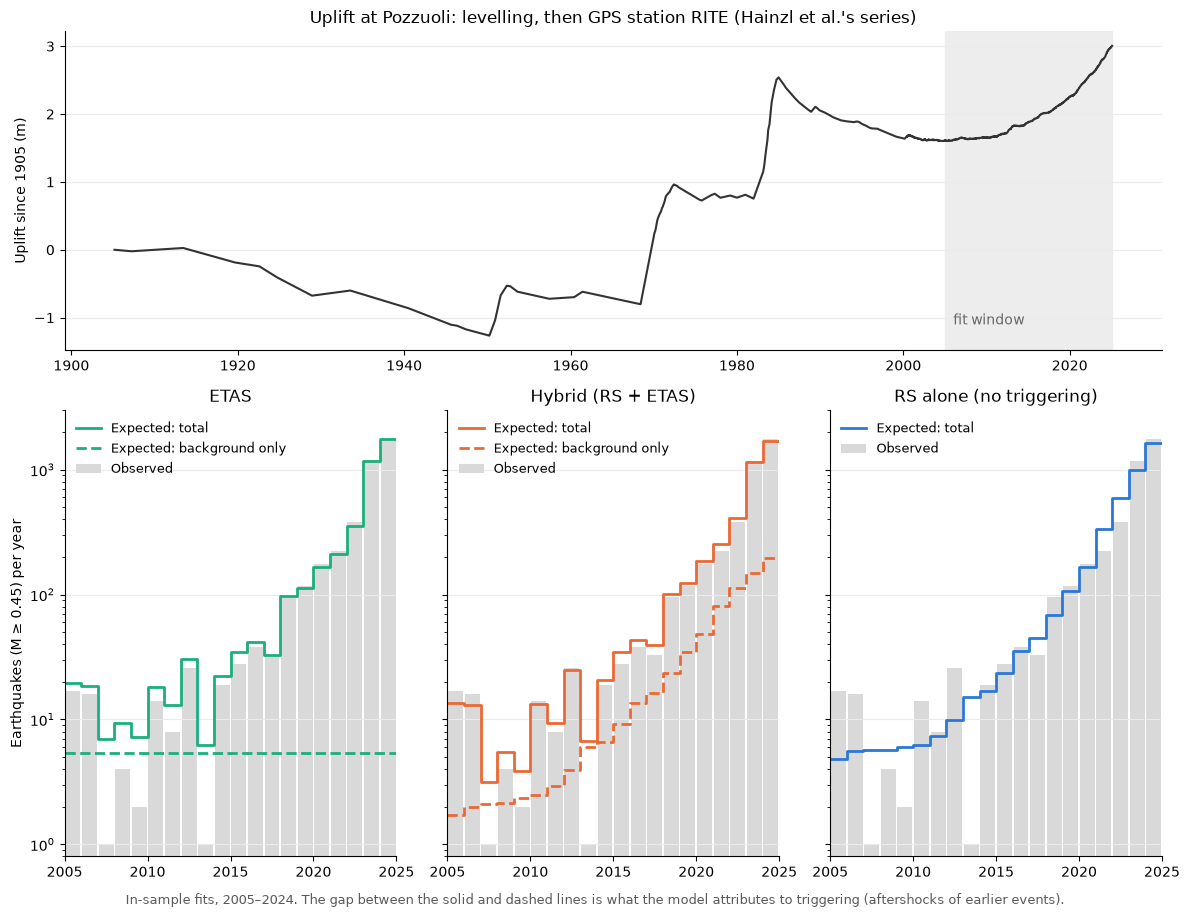

In [9]:
# Expected events per full calendar year in the window, split into background and triggered.
years = np.arange(2005, 2025)
edges = np.array([(pd.Timestamp(f"{y}-01-01", tz="UTC") - MJD_EPOCH) / pd.Timedelta(days=1)
                  for y in range(2005, 2026)])
observed = np.histogram(data["t"][data["target"]], edges)[0]

fig = plt.figure(figsize=(12, 9))
layout = fig.add_gridspec(2, 3, height_ratios=[1, 1.4])
top = fig.add_subplot(layout[0, :])
top.plot(uplift["year"], uplift["uplift"], color="0.2", linewidth=1.5)
top.axvspan(FIT_START_YEAR, uplift["year"].iloc[-1], color="0.93", zorder=0)
top.text(FIT_START_YEAR + 1, -1.1, "fit window", color="0.4")
top.set_ylabel("Uplift since 1905 (m)")
top.set_title("Uplift at Pozzuoli: levelling, then GPS station RITE (Hainzl et al.'s series)")
top.grid(True, axis="y", color="0.92", linewidth=0.8)
top.spines[["top", "right"]].set_visible(False)

step_x = np.append(years, years[-1] + 1)
first = None
for k, (model, title, colour) in enumerate([("etas", "ETAS", "#1baf7a"), ("rs_etas", "Hybrid (RS + ETAS)", "#eb6834"),
                                            ("rs", "RS alone (no triggering)", "#2a78d6")]):
    ax = fig.add_subplot(layout[1, k], sharey=first)
    first = first or ax
    e = expected_counts(fits[model]["params"], data, model, edges)
    total = (e["background"] + e["triggered"]).to_numpy()
    ax.bar(years + 0.5, observed, width=0.9, color="0.85", label="Observed")
    ax.step(step_x, np.append(total, total[-1]), where="post", color=colour, linewidth=2, label="Expected: total")
    if model != "rs":
        background = e["background"].to_numpy()
        ax.step(step_x, np.append(background, background[-1]), where="post", color=colour, linewidth=2,
                linestyle="--", label="Expected: background only")
    ax.set_yscale("log")
    ax.set_ylim(0.8, 3000)
    ax.set_xlim(2005, 2025)
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    ax.grid(True, axis="y", color="0.92", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    if k == 0:
        ax.set_ylabel(f"Earthquakes (M ≥ {MCUT}) per year")
    else:
        ax.tick_params(labelleft=False)
fig.text(0.5, -0.01, "In-sample fits, 2005–2024. The gap between the solid and dashed lines is what the model "
         "attributes to triggering (aftershocks of earlier events).", ha="center", fontsize=9, color="0.35")
plt.tight_layout()
plt.show()

**What section 1 shows:**

- **The catalogues agree.** Year by year, their catalogue and ours have the same number of M ≥ 0.45 events until 2023 (2024: 1,774 against 1,775). In 2025 they have 73 fewer, apparently because they downloaded it before INGV had finished reviewing the February 2025 swarm. Their fit window ends on 5 Feb 2025, before that swarm, so this doesn't affect the comparison.
- **The likelihood is theirs.** At their published parameters our −log L equals their files' to the third decimal (the last digit differs only because the files print the parameters to 6 significant figures).
- **Table 1 is reproduced.** Fitting from scratch gives r = 7.48 events/yr, Aσ′ = 0.197 m, t_a = 34.4 yr, K = 0.043, α = 0.24, p = 1.08, against 7.5, 0.20, 34.2, 0.04, 0.24, 1.08 in the paper. Our −log L is 0.02 better than theirs.
- **Several starts matter.** Four of five starts agree to 3–4 digits; one stopped in a different solution (r about 50 times smaller, t_a about 2,900 years) with a −log L about 4 worse. A single-start fit could have reported quite different physics.
- **The fitting method recovers known parameters.** Over 30 simulated catalogues, every parameter's average fit is within 0.7 standard errors of the truth, and the likelihood-ratio statistic averages 4.2 against a theoretical 5 (within its uncertainty). c and p are strongly correlated across fits (0.79): the trade-off the plan warned about, so small differences in c or p between fits mean little.
- **In sample, the uplift-driven background helps a lot.** The hybrid's AIC is 155 lower than ETAS's, for 2 extra parameters. RS alone, without triggering, is far worse than both: it gets the yearly level roughly right from about 2014 (within a factor of about 1.5; it overshoots 2021–2022) but can't explain the clustering within the year.
- **ETAS and the hybrid both match the yearly counts; they differ in how they explain them.** ETAS's background is constant by design (about 5 events a year: the dashed green line), so all the growth since 2005 has to come from triggering. It attributes 3% of events to the background (almost none by 2024), and its branching ratio is 0.97: each event produces almost one direct aftershock, so sequences barely die out, and its p of 1.00 makes the memory as long as possible. In effect ETAS treats the unrest as one self-sustaining sequence. The hybrid lets the uplift supply a growing background: it attributes 17% of events to it (20–30% in 2005–2022, 10–14% in the swarm-rich 2023–2024), and its branching ratio is a less extreme 0.82. For forecasting this should matter most after quiet spells, when ETAS's rate falls back towards its 5 events a year but the hybrid's background stays where the uplift puts it.
- **RS alone is essentially an exponential of the uplift.** Its fitted t_a is huge (about 1.5 million years), so the memory term does nothing and its rate is proportional to exp(uplift / 0.186 m): tenfold per 43 cm of uplift. The memory term only matters together with ETAS.
- The near-empty years 2007 and 2013 are gaps in the catalogue itself (phase 3), not quiet years.

These are in-sample fits on data to Feb 2025. Whether the hybrid's advantage survives as a week-ahead forecast made only with earlier data is the question for section 2 (milestone 4).